# BÀI THỰC HÀNH 2.2: XÂY DỰNG, TRỰC QUAN HÓA VÀ KIỂM THỬ DECISION TREE VỚI DỮ LIỆU IRIS
**Họ và tên:** Thái Anh Lạc  
**MSSV:** 089206000860  
**Mã lớp học phần:** 012012204103  
**Môn học:** Khai thác dữ liệu (Data Mining)


### Khởi tạo, cấu hình PATH cho Graphviz và import các thư viện cần thiết


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

for g_path in [r"C:\Program Files\Graphviz\bin", r"C:\Program Files (x86)\Graphviz\bin"]:
    if os.path.exists(g_path) and g_path not in os.environ['PATH']:
        os.environ['PATH'] = g_path + os.pathsep + os.environ['PATH']

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text, export_graphviz
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, classification_report
import graphviz

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Import thư viện và nạp Graphviz PATH thành công!")


Import thư viện và nạp Graphviz PATH thành công!


## 1. Nạp dữ liệu Iris vào bộ nhớ và hiển thị số thuộc tính (dimensionality), số objects (size)


In [2]:
iris = load_iris()
X = iris.data
feature_names = iris.feature_names
n_objects, n_features = X.shape

print("=== THÔNG TIN DỮ LIỆU IRIS ===")
print(f"Số lượng objects (Size / Số mẫu):        {n_objects} mẫu dữ liệu")
print(f"Số lượng thuộc tính (Dimensionality):    {n_features} thuộc tính")
print(f"Kích thước ma trận đặc trưng X:          {X.shape}")
for i, feat in enumerate(feature_names, 1):
    print(f"   {i}. {feat}")

df_features = pd.DataFrame(X, columns=feature_names)
print("\n=== 5 DÒNG ĐẦU TIÊN CỦA DỮ LIỆU ĐẶC TRƯNG ===")
print(df_features.head())


=== THÔNG TIN DỮ LIỆU IRIS ===
Số lượng objects (Size / Số mẫu):        150 mẫu dữ liệu
Số lượng thuộc tính (Dimensionality):    4 thuộc tính
Kích thước ma trận đặc trưng X:          (150, 4)
   1. sepal length (cm)
   2. sepal width (cm)
   3. petal length (cm)
   4. petal width (cm)

=== 5 DÒNG ĐẦU TIÊN CỦA DỮ LIỆU ĐẶC TRƯNG ===
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


## 2. Đặt nhãn (label) cho dữ liệu và hiển thị số lớp (classes)


In [3]:
y = iris.target
target_names = iris.target_names
classes, class_counts = np.unique(y, return_counts=True)

print("=== THÔNG TIN NHÃN VÀ CÁC LỚP ===")
print(f"Số lượng lớp phân loại (Number of Classes): {len(classes)} lớp")
for c, name, count in zip(classes, target_names, class_counts):
    print(f"   - Lớp {c} ({name:<15}): {count} mẫu ({count/len(y)*100:.1f}%)")


=== THÔNG TIN NHÃN VÀ CÁC LỚP ===
Số lượng lớp phân loại (Number of Classes): 3 lớp
   - Lớp 0 (setosa         ): 50 mẫu (33.3%)
   - Lớp 1 (versicolor     ): 50 mẫu (33.3%)
   - Lớp 2 (virginica      ): 50 mẫu (33.3%)


## 3. Tách dữ liệu thành 70% Training data và 30% Test data


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
print("=== KẾT QUẢ PHÂN CHIA TẬP DỮ LIỆU ===")
print(f"Số mẫu tập Huấn luyện (Training): {len(X_train)} mẫu (70%) | Shape: {X_train.shape}")
print(f"Số mẫu tập Kiểm thử (Testing):    {len(X_test)} mẫu (30%)  | Shape: {X_test.shape}")


=== KẾT QUẢ PHÂN CHIA TẬP DỮ LIỆU ===
Số mẫu tập Huấn luyện (Training): 105 mẫu (70%) | Shape: (105, 4)
Số mẫu tập Kiểm thử (Testing):    45 mẫu (30%)  | Shape: (45, 4)


## 4. Chuẩn hóa dữ liệu với StandardScaler


In [5]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("=== KẾT QUẢ CHUẨN HÓA DỮ LIỆU ===")
print("Mean sau chuẩn hóa (Train):", X_train_scaled.mean(axis=0).round(4))
print("Std sau chuẩn hóa (Train): ", X_train_scaled.std(axis=0).round(4))


=== KẾT QUẢ CHUẨN HÓA DỮ LIỆU ===
Mean sau chuẩn hóa (Train): [ 0. -0. -0. -0.]
Std sau chuẩn hóa (Train):  [1. 1. 1. 1.]


## 5. Tạo và huấn luyện mô hình DecisionTreeClassifier


In [6]:
clf = DecisionTreeClassifier(criterion='gini', random_state=42)
clf.fit(X_train_scaled, y_train)

train_acc = clf.score(X_train_scaled, y_train)
print("=== MÔ HÌNH MẶC ĐỊNH ĐÃ HUẤN LUYỆN THÀNH CÔNG ===")
print(f"Thuật toán:                  CART")
print(f"Độ sâu của cây (Max Depth):  {clf.get_depth()}")
print(f"Tổng số nút lá:              {clf.get_n_leaves()}")
print(f"Độ chính xác trên tập TRAIN: {train_acc * 100:.2f}% ({train_acc:.4f})  <-- Học thuộc lòng 100%")


=== MÔ HÌNH MẶC ĐỊNH ĐÃ HUẤN LUYỆN THÀNH CÔNG ===
Thuật toán:                  CART
Độ sâu của cây (Max Depth):  5
Tổng số nút lá:              8
Độ chính xác trên tập TRAIN: 100.00% (1.0000)  <-- Học thuộc lòng 100%


## 6. Test và đánh giá độ chính xác của mô hình (Confusion Matrix, Accuracy, F-score)


=== ĐÁNH GIÁ ĐỘ CHÍNH XÁC TRÊN TẬP TEST ===
1. Độ chính xác tập TRAIN:           100.00% (1.0000)  <-- 100.00%
2. Độ chính xác tập TEST (Accuracy): 91.11% (0.9111)
3. Độ chênh lệch Train - Test:       8.89%       <-- Dấu hiệu Overfitting
4. F1-Score Test (Weighted):         91.07% (0.9107)
5. F1-Score Test (Macro):            91.07% (0.9107)

=== BÁO CÁO PHÂN LOẠI CHI TIẾT ===
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        15
  versicolor     0.9231    0.8000    0.8571        15
   virginica     0.8235    0.9333    0.8750        15

    accuracy                         0.9111        45
   macro avg     0.9155    0.9111    0.9107        45
weighted avg     0.9155    0.9111    0.9107        45



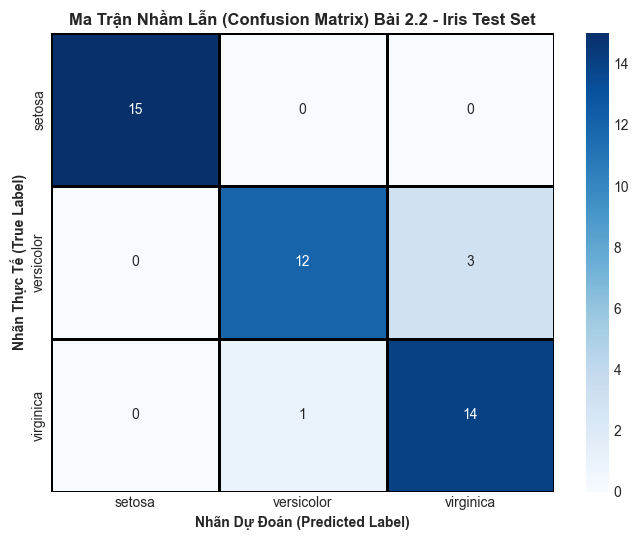

In [7]:
y_pred = clf.predict(X_test_scaled)
test_acc = accuracy_score(y_test, y_pred)
f1_weighted = f1_score(y_test, y_pred, average='weighted')
f1_macro = f1_score(y_test, y_pred, average='macro')
cm = confusion_matrix(y_test, y_pred)

print("=== ĐÁNH GIÁ ĐỘ CHÍNH XÁC TRÊN TẬP TEST ===")
print(f"1. Độ chính xác tập TRAIN:           {train_acc * 100:.2f}% ({train_acc:.4f})  <-- 100.00%")
print(f"2. Độ chính xác tập TEST (Accuracy): {test_acc * 100:.2f}% ({test_acc:.4f})")
print(f"3. Độ chênh lệch Train - Test:       {(train_acc - test_acc) * 100:.2f}%       <-- Dấu hiệu Overfitting")
print(f"4. F1-Score Test (Weighted):         {f1_weighted * 100:.2f}% ({f1_weighted:.4f})")
print(f"5. F1-Score Test (Macro):            {f1_macro * 100:.2f}% ({f1_macro:.4f})")

print("\n=== BÁO CÁO PHÂN LOẠI CHI TIẾT ===")
print(classification_report(y_test, y_pred, target_names=target_names, digits=4))

plt.figure(figsize=(7, 5.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names, cbar=True, linewidths=1, linecolor='black')
plt.title("Ma Trận Nhầm Lẫn (Confusion Matrix) Bài 2.2 - Iris Test Set", fontweight='bold', fontsize=12)
plt.xlabel("Nhãn Dự Đoán (Predicted Label)", fontweight='bold')
plt.ylabel("Nhãn Thực Tế (True Label)", fontweight='bold')
plt.tight_layout()
plt.show()


## 7. Trực quan hóa cây quyết định (Matplotlib, Graphviz, Text Rules)


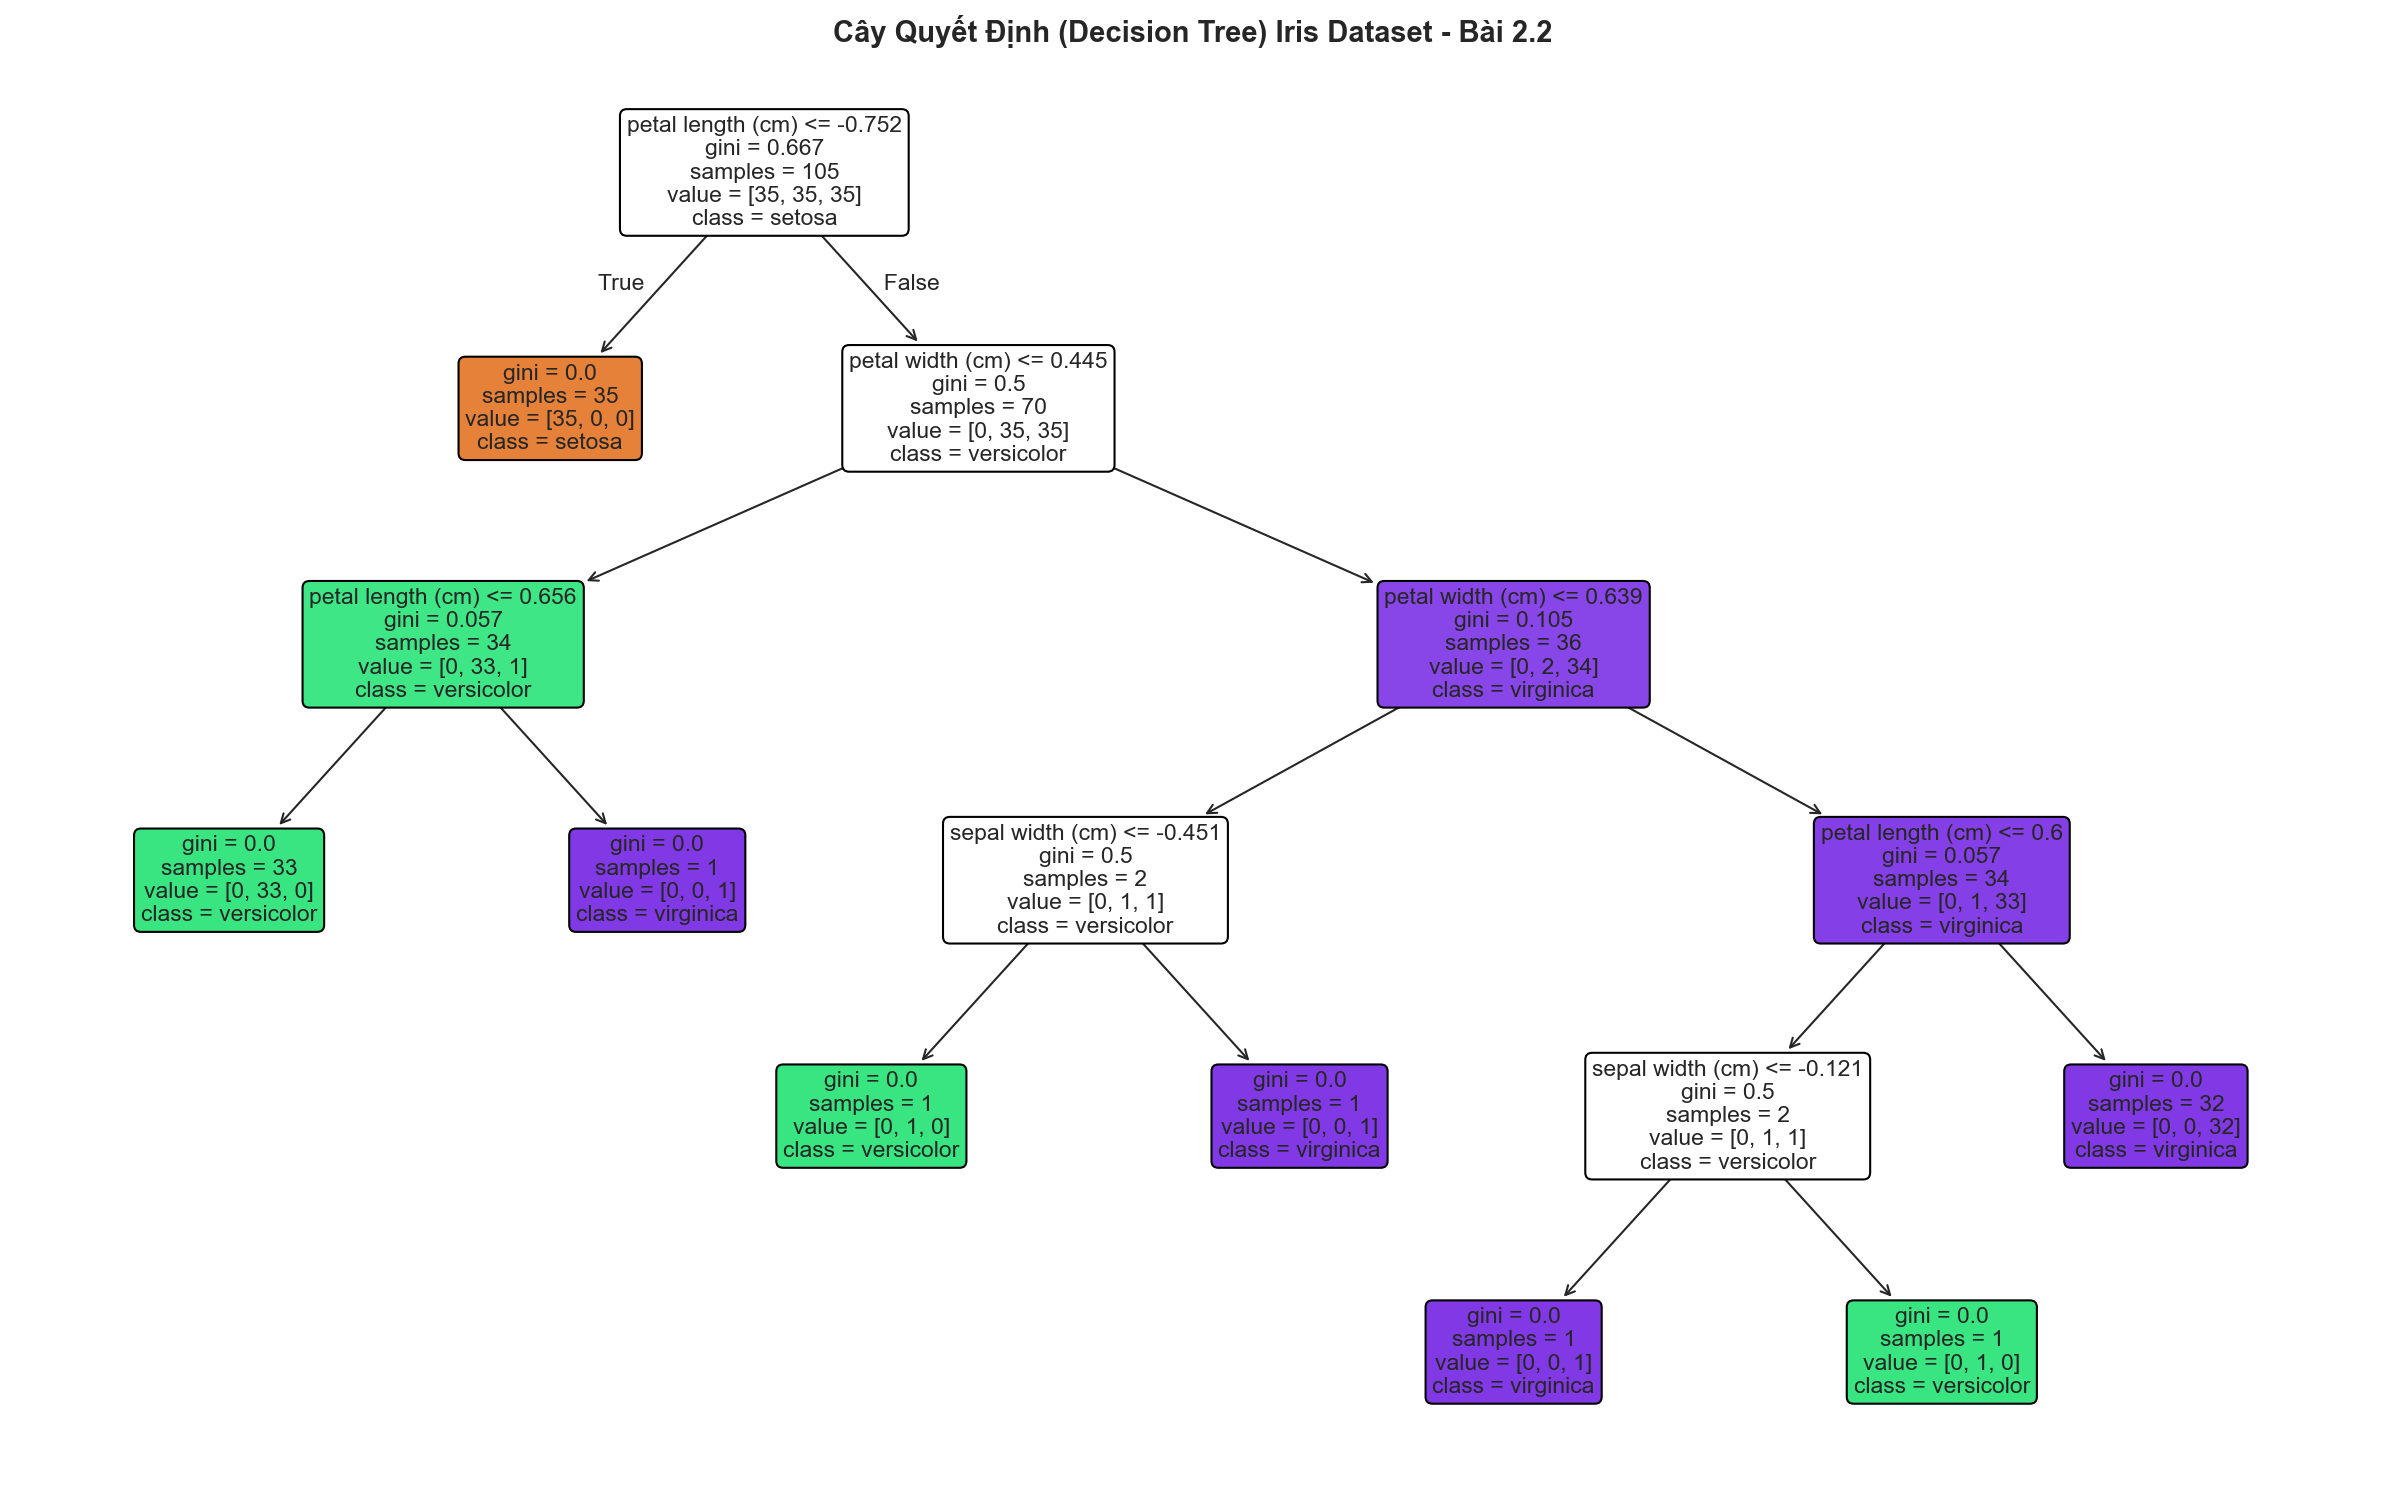

Đã xuất ảnh Graphviz 'iris_decision_tree.png'!

=== TẬP LUẬT DẠNG VĂN BẢN (TEXT RULES) ===
|--- petal length (cm) <= -0.75
|   |--- class: 0
|--- petal length (cm) >  -0.75
|   |--- petal width (cm) <= 0.44
|   |   |--- petal length (cm) <= 0.66
|   |   |   |--- class: 1
|   |   |--- petal length (cm) >  0.66
|   |   |   |--- class: 2
|   |--- petal width (cm) >  0.44
|   |   |--- petal width (cm) <= 0.64
|   |   |   |--- sepal width (cm) <= -0.45
|   |   |   |   |--- class: 1
|   |   |   |--- sepal width (cm) >  -0.45
|   |   |   |   |--- class: 2
|   |   |--- petal width (cm) >  0.64
|   |   |   |--- petal length (cm) <= 0.60
|   |   |   |   |--- sepal width (cm) <= -0.12
|   |   |   |   |   |--- class: 2
|   |   |   |   |--- sepal width (cm) >  -0.12
|   |   |   |   |   |--- class: 1
|   |   |   |--- petal length (cm) >  0.60
|   |   |   |   |--- class: 2



In [8]:
plt.figure(figsize=(16, 10), dpi=150)
plot_tree(clf, feature_names=feature_names, class_names=target_names, filled=True, rounded=True, fontsize=11)
plt.title("Cây Quyết Định (Decision Tree) Iris Dataset - Bài 2.2", fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

dot_data = export_graphviz(clf, out_file=None, feature_names=feature_names, class_names=target_names, filled=True, rounded=True)
try:
    graphviz.Source(dot_data).render("iris_decision_tree", format="png", cleanup=True)
    print("Đã xuất ảnh Graphviz 'iris_decision_tree.png'!")
except Exception as e:
    print("Graphviz render notice:", e)

print("\n=== TẬP LUẬT DẠNG VĂN BẢN (TEXT RULES) ===")
print(export_text(clf, feature_names=list(feature_names)))
